# Calibrated and Uncertainty-Aware Diabetes Risk Prediction Using Artificial Neural Networks
**21CSE326T - Artificial Neural Networks | Review II - Complete Project Notebook**

Team: Hareecharan R S (RA2411026050331) · V Shakthi Balan (RA2411026050334) · Manoranjan U S (RA2411026050305)

**Dataset:** CDC BRFSS 2015 Diabetes Health Indicators (binary file, 253,680 respondents, 21 features).

**Contents**
1. Setup and data loading
2. Schema validation and duplicate audit
3. Group-aware stratified train/test split (test set locked)
4. Preprocessing (fitted on training data only)
5. Model 1 - seven existing classifiers + stacking ensemble
6. Model 2 - ANN built from scratch in NumPy (focal loss, gradient check, MC dropout, temperature scaling)
7. Ablation study
8. Final evaluation on the locked test set (classification reports, confusion matrices, ROC, PR, calibration, McNemar, bootstrap CIs)
9. Uncertainty analysis ("refer to doctor")
10. Explainability (SHAP, per-patient explanation, what-if analysis)
11. Bias audit and false-negative analysis
12. Saving the model for the application

## 1. Setup and data loading

In [1]:
import json, os, time, warnings
os.environ["TQDM_DISABLE"] = "1"   # keep SHAP progress bars out of the notebook output
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold, RandomizedSearchCV, cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score, roc_auc_score,
                             average_precision_score, brier_score_loss, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
from statsmodels.stats.contingency_tables import mcnemar
from xgboost import XGBClassifier
import shap

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "axes.axisbelow": True, "font.size": 10})
BLUE, ORANGE, NAVY, RED, GREY = "#2a78d6", "#eb6834", "#1F3864", "#e34948", "#52514e"
MODEL_COLORS = {"Logistic Regression": "#7f8c8d", "KNN": "#b07aa1", "SVM (RBF)": "#9c755f", "Random Forest": "#59a14f",
                "XGBoost": "#4e79a7", "Gaussian NB": "#bab0ac", "MLP (sklearn)": "#76b7b2", "Stacking Ensemble": "#edc948",
                "Proposed ANN": ORANGE}

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "raw" / "diabetes_binary_health_indicators_BRFSS2015.csv"
OUT_FIG, OUT_RES, OUT_MODEL = ROOT / "reports" / "figures", ROOT / "reports" / "results", ROOT / "models"
for d in (OUT_FIG, OUT_RES, OUT_MODEL):
    d.mkdir(parents=True, exist_ok=True)

T0 = time.time()
raw = pd.read_csv(DATA)
print("Shape:", raw.shape)
raw.head()

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Shape: (253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


## 2. Schema validation and duplicate audit

In [2]:
TARGET = "Diabetes_binary"
BINARY = ["HighBP", "HighChol", "CholCheck", "Smoker", "Stroke", "HeartDiseaseorAttack", "PhysActivity", "Fruits",
          "Veggies", "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"]
CONTINUOUS = ["BMI", "MentHlth", "PhysHlth"]
ORDINAL = ["GenHlth", "Age", "Education", "Income"]
FEATURES = BINARY + CONTINUOUS + ORDINAL
RANGES = {TARGET: (0, 1), **{c: (0, 1) for c in BINARY}, "BMI": (12, 98), "MentHlth": (0, 30), "PhysHlth": (0, 30),
          "GenHlth": (1, 5), "Age": (1, 13), "Education": (1, 6), "Income": (1, 8)}

checks = pd.DataFrame({
    "missing": raw.isna().sum(),
    "non_integer": (raw != raw.round()).sum(),
    "out_of_range": pd.Series({c: int(((raw[c] < lo) | (raw[c] > hi)).sum()) for c, (lo, hi) in RANGES.items()}),
    "min": raw.min(), "max": raw.max(),
})
assert checks[["missing", "non_integer", "out_of_range"]].values.sum() == 0, "schema problem"
df = raw.astype(np.int64)
print("Schema valid: 0 missing, 0 non-integer, 0 out-of-range values")
print("Class counts:", df[TARGET].value_counts().to_dict(), f"-> positive rate {df[TARGET].mean():.2%}")

dup_mask = df.duplicated(keep="first")
print(f"Exact duplicate rows: {dup_mask.sum():,} ({dup_mask.mean():.2%}); unique rows: {(~dup_mask).sum():,}")
print(f"Positive rate if duplicates were dropped: {df.loc[~dup_mask, TARGET].mean():.2%} (kept instead, see split)")

Schema valid: 0 missing, 0 non-integer, 0 out-of-range values
Class counts: {0: 218334, 1: 35346} -> positive rate 13.93%


Exact duplicate rows: 24,206 (9.54%); unique rows: 229,474
Positive rate if duplicates were dropped: 15.29% (kept instead, see split)


## 3. Group-aware stratified train/test split (test set locked)
Identical rows are grouped so that no test row has an exact copy in the training set; stratification keeps the real 13.93% prevalence. The test set is not used again until Section 8.

In [3]:
groups = df.groupby(df.columns.tolist(), sort=False).ngroup().to_numpy()
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_idx, te_idx = next(sgkf.split(df, df[TARGET], groups))
train, test = df.iloc[tr_idx].reset_index(drop=True), df.iloc[te_idx].reset_index(drop=True)
g_train = groups[tr_idx]
shared = len(set(map(tuple, train.to_numpy())) & set(map(tuple, test.to_numpy())))
print(f"Train: {len(train):,} rows ({train[TARGET].mean():.2%} positive) | Test: {len(test):,} rows ({test[TARGET].mean():.2%} positive)")
print("Identical rows shared between train and test:", shared)

# Validation split carved from the training set (also group-aware) for early stopping, calibration and thresholds
fit_i, val_i = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(train, train[TARGET], g_train))
fit, val = train.iloc[fit_i].reset_index(drop=True), train.iloc[val_i].reset_index(drop=True)
g_fit = g_train[fit_i]
print(f"Fit: {len(fit):,} | Validation: {len(val):,}")

Train: 202,944 rows (13.93% positive) | Test: 50,736 rows (13.93% positive)
Identical rows shared between train and test: 0


Fit: 162,355 | Validation: 40,589


## 4. Preprocessing (fitted on training data only)
BMI is clipped at the training 1st/99th percentiles; BMI, MentHlth and PhysHlth are standardised; ordinal bands keep their integer codes and binary features stay 0/1. For the neural networks, ordinal codes are also min-max scaled to [0, 1].

In [4]:
class Preprocessor:
    """Fit on training data; apply identical transformation everywhere (notebook and app)."""
    def fit(self, X: pd.DataFrame):
        self.lo_, self.hi_ = np.percentile(X["BMI"], [1, 99])
        Z = X.copy(); Z["BMI"] = Z["BMI"].clip(self.lo_, self.hi_)
        self.mu_, self.sd_ = Z[CONTINUOUS].mean(), Z[CONTINUOUS].std(ddof=0)
        self.omin_ = pd.Series({c: RANGES[c][0] for c in ORDINAL}); self.omax_ = pd.Series({c: RANGES[c][1] for c in ORDINAL})
        return self
    def transform(self, X: pd.DataFrame, nn: bool = False) -> np.ndarray:
        Z = X[FEATURES].copy().astype(float)
        Z["BMI"] = Z["BMI"].clip(self.lo_, self.hi_)
        Z[CONTINUOUS] = (Z[CONTINUOUS] - self.mu_) / self.sd_
        if nn:
            Z[ORDINAL] = (Z[ORDINAL] - self.omin_) / (self.omax_ - self.omin_)
        return Z.to_numpy()

prep = Preprocessor().fit(fit[FEATURES])
X_fit, X_val, X_te = prep.transform(fit), prep.transform(val), prep.transform(test)
Xn_fit, Xn_val, Xn_te = prep.transform(fit, nn=True), prep.transform(val, nn=True), prep.transform(test, nn=True)
y_fit, y_val, y_te = fit[TARGET].to_numpy(), val[TARGET].to_numpy(), test[TARGET].to_numpy()
print(f"BMI clipping bounds (training 1st/99th pct): [{prep.lo_:.0f}, {prep.hi_:.0f}]")
print("Feature matrix shapes:", X_fit.shape, X_val.shape, X_te.shape)

BMI clipping bounds (training 1st/99th pct): [18, 50]
Feature matrix shapes: (162355, 21) (40589, 21) (50736, 21)


## 5. Model 1 - seven existing classifiers + stacking ensemble
Imbalance is handled with class weights where the algorithm supports them; every model's decision threshold is then tuned on the validation set by maximising F2 (recall weighted twice as heavily as precision). Hyperparameters are tuned with a small randomized search (3-fold group-aware CV on a 40,000-row stratified sample) to fit the compute budget; KNN and SVM are trained on a 25,000-row stratified sample because of their quadratic cost.

In [5]:
rng = np.random.default_rng(SEED)
def strat_sample(n, y, seed=SEED):
    idx = np.arange(len(y)); out = []
    for c in (0, 1):
        ci = idx[y == c]; out.append(np.random.default_rng(seed).choice(ci, int(round(n * len(ci) / len(y))), replace=False))
    return np.sort(np.concatenate(out))

spw = float((y_fit == 0).sum() / (y_fit == 1).sum())
s40 = strat_sample(40000, y_fit); s25 = strat_sample(25000, y_fit)
cv3 = list(GroupKFold(n_splits=3).split(X_fit[s40], y_fit[s40], g_fit[s40]))

def tune(est, grid, n_iter):
    rs = RandomizedSearchCV(est, grid, n_iter=n_iter, scoring="average_precision", cv=cv3, random_state=SEED, n_jobs=2)
    rs.fit(X_fit[s40], y_fit[s40]); return rs.best_params_, rs.best_score_

tuning = {}
t = time.time()
p, s = tune(LogisticRegression(max_iter=3000, class_weight="balanced"), {"C": [0.01, 0.1, 1, 10]}, 4); tuning["Logistic Regression"] = (p, s)
p, s = tune(RandomForestClassifier(n_estimators=150, class_weight="balanced_subsample", random_state=SEED, n_jobs=2),
            {"max_depth": [8, 12, 16, None], "min_samples_leaf": [5, 20, 50], "max_features": ["sqrt", 0.5]}, 6); tuning["Random Forest"] = (p, s)
p, s = tune(XGBClassifier(n_estimators=300, tree_method="hist", scale_pos_weight=spw, random_state=SEED, n_jobs=2, eval_metric="logloss"),
            {"max_depth": [3, 4, 5, 6], "learning_rate": [0.03, 0.05, 0.1], "subsample": [0.8, 1.0], "colsample_bytree": [0.7, 0.9]}, 8); tuning["XGBoost"] = (p, s)
p, s = tune(KNeighborsClassifier(), {"n_neighbors": [25, 51, 101, 151]}, 4); tuning["KNN"] = (p, s)
print(f"Tuning done in {time.time() - t:.0f}s")
pd.DataFrame({m: {"best params": str(v[0]), "CV PR-AUC (40k sample)": round(v[1], 4)} for m, v in tuning.items()}).T

Tuning done in 57s


,best params,CV PR-AUC (40k sample)
Logistic Regression,{'C': 10},0.4082
Random Forest,"{'min_samples_leaf': 50, 'max_features': 'sqrt...",0.4096
XGBoost,"{'subsample': 0.8, 'max_depth': 3, 'learning_r...",0.4158
KNN,{'n_neighbors': 151},0.3874


In [6]:
def platt(scores_val, y, scores_other):
    lr = LogisticRegression().fit(scores_val.reshape(-1, 1), y)
    return lr.predict_proba(scores_other.reshape(-1, 1))[:, 1]

models, P_val, P_te, fit_time = {}, {}, {}, {}
spec = {
    "Logistic Regression": (LogisticRegression(max_iter=3000, class_weight="balanced", **tuning["Logistic Regression"][0]), None),
    "KNN": (KNeighborsClassifier(**tuning["KNN"][0]), s25),
    "SVM (RBF)": (SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=SEED), s25),
    "Random Forest": (RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=SEED, n_jobs=2, **tuning["Random Forest"][0]), None),
    "XGBoost": (XGBClassifier(n_estimators=300, tree_method="hist", scale_pos_weight=spw, random_state=SEED, n_jobs=2, eval_metric="logloss", **tuning["XGBoost"][0]), None),
    "Gaussian NB": (GaussianNB(), None),
    "MLP (sklearn)": (MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=60, random_state=SEED), None),
}
for name, (est, sub) in spec.items():
    t = time.time()
    Xs, ys = (X_fit, y_fit) if sub is None else (X_fit[sub], y_fit[sub])
    est.fit(Xs, ys)
    if name == "SVM (RBF)":   # decision scores -> probabilities with Platt scaling fitted on the validation set
        sv, st = est.decision_function(X_val), est.decision_function(X_te)
        P_val[name], P_te[name] = platt(sv, y_val, sv), platt(sv, y_val, st)
    else:
        P_val[name], P_te[name] = est.predict_proba(X_val)[:, 1], est.predict_proba(X_te)[:, 1]
    models[name], fit_time[name] = est, time.time() - t
    print(f"{name:20s} trained on {len(ys):,} rows in {fit_time[name]:5.1f}s | val PR-AUC {average_precision_score(y_val, P_val[name]):.4f} | val ROC-AUC {roc_auc_score(y_val, P_val[name]):.4f}")

Logistic Regression  trained on 162,355 rows in   3.6s | val PR-AUC 0.4206 | val ROC-AUC 0.8248


KNN                  trained on 25,000 rows in   9.1s | val PR-AUC 0.3878 | val ROC-AUC 0.8120


SVM (RBF)            trained on 25,000 rows in  82.3s | val PR-AUC 0.4180 | val ROC-AUC 0.8272


Random Forest        trained on 162,355 rows in  18.3s | val PR-AUC 0.4316 | val ROC-AUC 0.8282


XGBoost              trained on 162,355 rows in   2.0s | val PR-AUC 0.4356 | val ROC-AUC 0.8309
Gaussian NB          trained on 162,355 rows in   0.1s | val PR-AUC 0.3498 | val ROC-AUC 0.7864


MLP (sklearn)        trained on 162,355 rows in  16.0s | val PR-AUC 0.4291 | val ROC-AUC 0.8292


**Stacking ensemble.** A logistic-regression meta-learner combines the base models' validation-set probabilities (blending). Its own validation predictions come from 5-fold cross-validation inside the validation set, so its threshold is not tuned on predictions it was trained on.

In [7]:
BASE = ["Logistic Regression", "Random Forest", "XGBoost", "MLP (sklearn)", "KNN", "SVM (RBF)"]
Z_val = np.column_stack([P_val[m] for m in BASE]); Z_te = np.column_stack([P_te[m] for m in BASE])
meta = LogisticRegression(max_iter=2000)
P_val["Stacking Ensemble"] = cross_val_predict(meta, Z_val, y_val, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
meta.fit(Z_val, y_val)
P_te["Stacking Ensemble"] = meta.predict_proba(Z_te)[:, 1]
print("Meta-learner weights:", dict(zip(BASE, np.round(meta.coef_[0], 3))))
print(f"Stacking val PR-AUC {average_precision_score(y_val, P_val['Stacking Ensemble']):.4f} | ROC-AUC {roc_auc_score(y_val, P_val['Stacking Ensemble']):.4f}")

Meta-learner weights: {'Logistic Regression': np.float64(0.125), 'Random Forest': np.float64(1.262), 'XGBoost': np.float64(3.583), 'MLP (sklearn)': np.float64(0.925), 'KNN': np.float64(0.336), 'SVM (RBF)': np.float64(-0.602)}
Stacking val PR-AUC 0.4328 | ROC-AUC 0.8307


## 6. Model 2 - ANN built from scratch in NumPy
Architecture: input (21) → Dense 64 + ReLU → Dropout 0.2 → Dense 32 + ReLU → Dropout 0.2 → Dense 1 (logit) → sigmoid.
Training: mini-batch Adam, He initialisation, early stopping on validation PR-AUC.

**Novelty components**
* **Class-weighted focal loss** - $FL = -\alpha\,y\,(1-p)^{\gamma}\log p \;-\; (1-\alpha)(1-y)\,p^{\gamma}\log(1-p)$, gradient derived by hand with respect to the logit $z$:
  $\partial FL/\partial z = \alpha(1-p)^{\gamma}\,[\gamma p\log p-(1-p)]$ for $y=1$ and $(1-\alpha)\,p^{\gamma}\,[p-\gamma(1-p)\log(1-p)]$ for $y=0$.
* **Monte Carlo dropout** - dropout stays active at inference; 50 stochastic passes give a mean risk $\mu$ and an uncertainty $\sigma$.
* **Temperature scaling with a bias term** - logits are mapped to $z/T + b$ before the sigmoid; $T$ and $b$ are fitted on the validation set by minimum negative log-likelihood. The bias is needed because focal loss with class weighting shifts the model's base rate, which a temperature alone cannot undo.
* **Abstention** - the decision margin $m = |\mu - t| / \sigma$ measures how many MC standard deviations the mean risk lies from the decision threshold $t$. Cases with $m$ below a validation-chosen $\tau$ (the model could easily land on either side of the threshold) are flagged "refer to doctor".

In [8]:
def sigmoid(z):
    return np.where(z >= 0, 1 / (1 + np.exp(-z)), np.exp(z) / (1 + np.exp(z)))

class Dense:
    def __init__(self, n_in, n_out, rng):
        self.W = rng.normal(0, np.sqrt(2.0 / n_in), (n_in, n_out)); self.b = np.zeros(n_out)
    def forward(self, x): self.x = x; return x @ self.W + self.b
    def backward(self, g): self.dW = self.x.T @ g; self.db = g.sum(0); return g @ self.W.T
    def params(self): return [(self.W, "dW"), (self.b, "db")]

class ReLU:
    def forward(self, x): self.m = x > 0; return x * self.m
    def backward(self, g): return g * self.m
    def params(self): return []

class Dropout:
    def __init__(self, rate, rng): self.rate, self.rng, self.active = rate, rng, False
    def forward(self, x):
        if not self.active or self.rate == 0: return x
        self.mask = (self.rng.random(x.shape) >= self.rate) / (1 - self.rate); return x * self.mask
    def backward(self, g): return g * self.mask if self.active and self.rate > 0 else g
    def params(self): return []

def bce_loss(z, y, w_pos=1.0):
    """(Weighted) binary cross-entropy on logits; returns mean loss and dL/dz."""
    p = sigmoid(z); w = np.where(y == 1, w_pos, 1.0)
    loss = -(w * (y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))).mean()
    return loss, w * (p - y) / len(y)

def focal_loss(z, y, alpha=0.75, gamma=2.0):
    """Class-weighted focal loss on logits with the hand-derived gradient dFL/dz."""
    p = np.clip(sigmoid(z), 1e-12, 1 - 1e-12)
    loss = np.where(y == 1, -alpha * (1 - p) ** gamma * np.log(p), -(1 - alpha) * p ** gamma * np.log(1 - p))
    grad = np.where(y == 1, alpha * (1 - p) ** gamma * (gamma * p * np.log(p) - (1 - p)),
                    (1 - alpha) * p ** gamma * (p - gamma * (1 - p) * np.log(1 - p)))
    return loss.mean(), grad / len(y)

class ScratchANN:
    def __init__(self, n_in, hidden=(64, 32), dropout=0.2, seed=SEED):
        self.rng = np.random.default_rng(seed); layers = []; d = n_in
        for h in hidden:
            layers += [Dense(d, h, self.rng), ReLU(), Dropout(dropout, self.rng)]; d = h
        layers.append(Dense(d, 1, self.rng)); self.layers = layers
    def set_dropout(self, on):
        for l in self.layers:
            if isinstance(l, Dropout): l.active = on
    def logits(self, X):
        h = X
        for l in self.layers: h = l.forward(h)
        return h[:, 0]
    def backward(self, dz):
        g = dz[:, None]
        for l in reversed(self.layers): g = l.backward(g)
    def params(self):
        return [(p, l, g) for l in self.layers for p, g in l.params()]
    def predict_logits(self, X, mc=False, T=1):
        self.set_dropout(mc)
        if not mc: return self.logits(X)
        return np.stack([self.logits(X) for _ in range(T)])

class Adam:
    def __init__(self, model, lr=1e-3, b1=0.9, b2=0.999, eps=1e-8):
        self.m, self.lr, self.b1, self.b2, self.eps, self.t = model, lr, b1, b2, eps, 0
        self.s = [(np.zeros_like(p), np.zeros_like(p)) for p, _, _ in model.params()]
    def step(self):
        self.t += 1
        for k, (p, layer, gname) in enumerate(self.m.params()):
            g = getattr(layer, gname); m, v = self.s[k]
            m[:] = self.b1 * m + (1 - self.b1) * g; v[:] = self.b2 * v + (1 - self.b2) * g * g
            mh, vh = m / (1 - self.b1 ** self.t), v / (1 - self.b2 ** self.t)
            p -= self.lr * mh / (np.sqrt(vh) + self.eps)

### 6.1 Numerical gradient check
Backpropagation is verified against central differences ($\varepsilon = 10^{-5}$) on a small batch, for both losses. Relative errors around $10^{-7}$ or lower confirm the hand-derived gradients.

In [9]:
def grad_check(loss_fn, n=16, eps=1e-5, **kw):
    net = ScratchANN(X_fit.shape[1], hidden=(8, 4), dropout=0.0, seed=1)
    Xb, yb = Xn_fit[:n].astype(np.float64), y_fit[:n].astype(np.float64)
    yb[:4] = 1
    _, dz = loss_fn(net.logits(Xb), yb, **kw); net.backward(dz)
    worst = 0.0
    for p, layer, gname in net.params():
        ana = getattr(layer, gname).copy(); num = np.zeros_like(p); it = np.nditer(p, flags=["multi_index"])
        for _ in it:
            i = it.multi_index; old = p[i]
            p[i] = old + eps; lp, _ = loss_fn(net.logits(Xb), yb, **kw)
            p[i] = old - eps; lm, _ = loss_fn(net.logits(Xb), yb, **kw)
            p[i] = old; num[i] = (lp - lm) / (2 * eps)
        rel = np.linalg.norm(ana - num) / max(np.linalg.norm(ana) + np.linalg.norm(num), 1e-12)
        worst = max(worst, rel)
    return worst

gc = {"BCE": grad_check(bce_loss), "Focal (alpha=0.75, gamma=2)": grad_check(focal_loss, alpha=0.75, gamma=2.0)}
for k, v in gc.items():
    print(f"Gradient check - {k:28s} max relative error = {v:.2e}  {'PASS' if v < 1e-6 else 'FAIL'}")

Gradient check - BCE                          max relative error = 3.60e-11  PASS
Gradient check - Focal (alpha=0.75, gamma=2)  max relative error = 1.33e-10  PASS


### 6.2 Training

In [10]:
def train_ann(loss="focal", alpha=0.75, gamma=2.0, w_pos=1.0, dropout=0.2, epochs=40, batch=512, lr=1e-3, patience=6, seed=SEED, verbose=False):
    net = ScratchANN(Xn_fit.shape[1], dropout=dropout, seed=seed); opt = Adam(net, lr=lr)
    Xf, yf = Xn_fit.astype(np.float32), y_fit.astype(np.float32)
    best, best_w, wait, hist = -1, None, 0, []
    r = np.random.default_rng(seed)
    for ep in range(epochs):
        net.set_dropout(True); order = r.permutation(len(yf)); tot = 0
        for s in range(0, len(order), batch):
            b = order[s:s + batch]; z = net.logits(Xf[b])
            l, dz = focal_loss(z, yf[b], alpha, gamma) if loss == "focal" else bce_loss(z, yf[b], w_pos)
            net.backward(dz.astype(np.float32)); opt.step(); tot += l * len(b)
        pv = sigmoid(net.predict_logits(Xn_val.astype(np.float32)))
        ap = average_precision_score(y_val, pv); hist.append((ep + 1, tot / len(yf), ap))
        if verbose: print(f"epoch {ep + 1:2d}  train loss {tot / len(yf):.4f}  val PR-AUC {ap:.4f}")
        if ap > best + 1e-4:
            best, wait = ap, 0; best_w = [p.copy() for p, _, _ in net.params()]
        else:
            wait += 1
            if wait >= patience: break
    for (p, _, _), w in zip(net.params(), best_w): p[...] = w
    return net, best, pd.DataFrame(hist, columns=["epoch", "train_loss", "val_pr_auc"])

# Small search over focal-loss parameters (selected on validation PR-AUC)
t = time.time(); search = []
for a in (0.75, 0.86):
    for g in (1.0, 2.0):
        _, ap, h = train_ann("focal", alpha=a, gamma=g, epochs=25, patience=4)
        search.append({"alpha": a, "gamma": g, "val PR-AUC": round(ap, 4), "epochs run": len(h)})
search = pd.DataFrame(search).sort_values("val PR-AUC", ascending=False)
print(f"Focal-loss search done in {time.time() - t:.0f}s"); display(search)
ALPHA, GAMMA = float(search.iloc[0]["alpha"]), float(search.iloc[0]["gamma"])

Focal-loss search done in 47s


,alpha,gamma,val PR-AUC,epochs run
3,0.86,2.0,0.4343,25
2,0.86,1.0,0.4332,25
1,0.75,2.0,0.4329,16
0,0.75,1.0,0.4322,18


epoch  1  train loss 0.0393  val PR-AUC 0.3890


epoch  2  train loss 0.0337  val PR-AUC 0.4164


epoch  3  train loss 0.0330  val PR-AUC 0.4214


epoch  4  train loss 0.0326  val PR-AUC 0.4245


epoch  5  train loss 0.0324  val PR-AUC 0.4267


...

epoch 27  train loss 0.0313  val PR-AUC 0.4344


epoch 28  train loss 0.0312  val PR-AUC 0.4341


epoch 29  train loss 0.0312  val PR-AUC 0.4339


epoch 30  train loss 0.0313  val PR-AUC 0.4338


epoch 31  train loss 0.0312  val PR-AUC 0.4336
Final ANN (alpha=0.86, gamma=2.0) trained in 18s; best val PR-AUC 0.4343


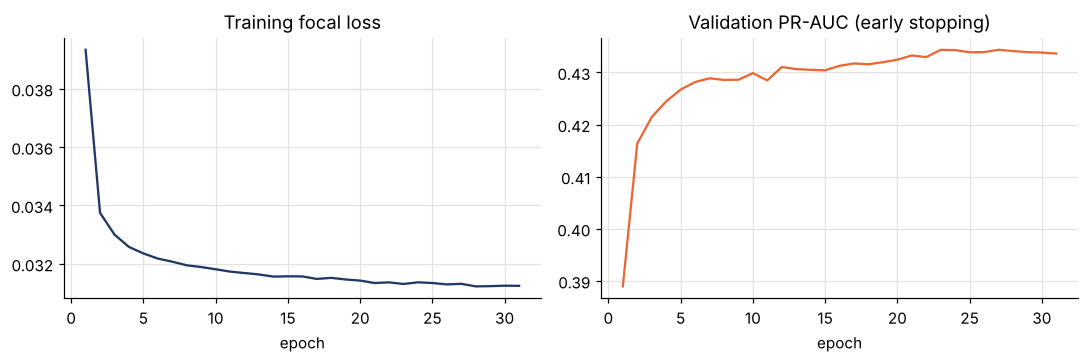

In [11]:
t = time.time()
ann, ann_best, ann_hist = train_ann("focal", alpha=ALPHA, gamma=GAMMA, epochs=60, patience=8, verbose=True)
print(f"Final ANN (alpha={ALPHA}, gamma={GAMMA}) trained in {time.time() - t:.0f}s; best val PR-AUC {ann_best:.4f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(ann_hist.epoch, ann_hist.train_loss, color=NAVY); ax[0].set_title("Training focal loss"); ax[0].set_xlabel("epoch")
ax[1].plot(ann_hist.epoch, ann_hist.val_pr_auc, color=ORANGE); ax[1].set_title("Validation PR-AUC (early stopping)"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(OUT_FIG / "r2_ann_training_curves.png", dpi=200); plt.show()

### 6.3 Monte Carlo dropout and calibration (temperature scaling with bias)

In [12]:
T_MC = 50
def mc_predict(net, X, cal=(1.0, 0.0), passes=T_MC, seed=SEED):
    for l in net.layers:
        if isinstance(l, Dropout): l.rng = np.random.default_rng(seed)
    Z = net.predict_logits(X.astype(np.float32), mc=True, T=passes)
    P = sigmoid(Z / cal[0] + cal[1])
    return P.mean(0), P.std(0)

def fit_calibration(net, X, y):
    """Fit temperature T and bias b on the averaged MC-dropout prediction (minimum NLL)."""
    for l in net.layers:
        if isinstance(l, Dropout): l.rng = np.random.default_rng(SEED)
    Z = net.predict_logits(X.astype(np.float32), mc=True, T=T_MC)
    def nll(v):
        p = np.clip(sigmoid(Z / np.exp(v[0]) + v[1]).mean(0), 1e-12, 1 - 1e-12)
        return -(y * np.log(p) + (1 - y) * np.log(1 - p)).mean()
    r = minimize(nll, x0=[0.0, 0.0], method="Nelder-Mead", options={"xatol": 1e-4, "fatol": 1e-7})
    return float(np.exp(r.x[0])), float(r.x[1])

mu_val_raw, sd_val_raw = mc_predict(ann, Xn_val)
CAL = fit_calibration(ann, Xn_val, y_val)
TEMP, BIAS = CAL
mu_val, sd_val = mc_predict(ann, Xn_val, cal=CAL)
print(f"Fitted temperature T = {TEMP:.3f}, bias b = {BIAS:.3f}")
print(f"Validation Brier score: before {brier_score_loss(y_val, mu_val_raw):.4f} -> after {brier_score_loss(y_val, mu_val):.4f}")
print(f"Validation mean predicted risk: before {mu_val_raw.mean():.3f} -> after {mu_val.mean():.3f} (true rate {y_val.mean():.3f})")
P_val["Proposed ANN"] = mu_val

Fitted temperature T = 0.347, bias b = -1.786
Validation Brier score: before 0.1845 -> after 0.0967
Validation mean predicted risk: before 0.426 -> after 0.139 (true rate 0.139)


## 7. Thresholds and ablation study
Decision thresholds are chosen on the validation set by maximising F2. The abstention threshold $\tau$ is the 10th percentile of the validation decision margin $|\mu - t|/\sigma$ (the 10% least certain decisions are referred). The ablation trains each variant with the same architecture and evaluates it on the validation set.

In [13]:
def f2_threshold(y, p):
    grid = np.linspace(0.02, 0.98, 97)
    scores = [fbeta_score(y, (p >= t).astype(int), beta=2) for t in grid]
    return float(grid[int(np.argmax(scores))])

THR = {m: f2_threshold(y_val, P_val[m]) for m in P_val}
def margin(mu, sd, thr):
    return np.abs(mu - thr) / (sd + 1e-9)
TAU = float(np.quantile(margin(mu_val, sd_val, THR["Proposed ANN"]), 0.10))
print("F2-optimal thresholds (validation):", {k: round(v, 2) for k, v in THR.items()})
print(f"Abstention threshold tau (decision margin, 10th percentile on validation) = {TAU:.3f}")

t = time.time(); abl = []
variants = [("Plain MLP (BCE, no weighting)", dict(loss="bce", w_pos=1.0)),
            ("+ class-weighted BCE", dict(loss="bce", w_pos=spw)),
            ("+ class-weighted focal loss", dict(loss="focal", alpha=ALPHA, gamma=GAMMA))]
for name, kw in variants:
    net, _, _ = train_ann(epochs=40, patience=6, **kw) if "focal" not in name else (ann, None, None)
    p = sigmoid(net.predict_logits(Xn_val.astype(np.float32)))
    th = f2_threshold(y_val, p)
    abl.append({"variant": name, "PR-AUC": average_precision_score(y_val, p), "ROC-AUC": roc_auc_score(y_val, p),
                "Brier": brier_score_loss(y_val, p), "Recall@F2": recall_score(y_val, p >= th), "F2": fbeta_score(y_val, p >= th, beta=2)})
p = mu_val; th = THR["Proposed ANN"]
abl.append({"variant": "+ MC dropout (50 passes) + calibration", "PR-AUC": average_precision_score(y_val, p), "ROC-AUC": roc_auc_score(y_val, p),
            "Brier": brier_score_loss(y_val, p), "Recall@F2": recall_score(y_val, p >= th), "F2": fbeta_score(y_val, p >= th, beta=2)})
abl = pd.DataFrame(abl).round(4)
print(f"Ablation done in {time.time() - t:.0f}s"); abl.to_csv(OUT_RES / "r2_ablation.csv", index=False); abl

F2-optimal thresholds (validation): {'Logistic Regression': 0.43, 'KNN': 0.12, 'SVM (RBF)': 0.11, 'Random Forest': 0.45, 'XGBoost': 0.47, 'Gaussian NB': 0.03, 'MLP (sklearn)': 0.12, 'Stacking Ensemble': 0.1, 'Proposed ANN': 0.12}
Abstention threshold tau (decision margin, 10th percentile on validation) = 1.101


Ablation done in 33s


,variant,PR-AUC,ROC-AUC,Brier,Recall@F2,F2
0,"Plain MLP (BCE, no weighting)",0.4318,0.8305,0.0967,0.8453,0.6073
1,+ class-weighted BCE,0.4333,0.8299,0.1708,0.8571,0.6065
2,+ class-weighted focal loss,0.4343,0.8297,0.1847,0.8389,0.6064
3,+ MC dropout (50 passes) + calibration,0.4345,0.8296,0.0967,0.8410,0.6064


## 8. Final evaluation on the locked test set
The test set is used **once**, here, with every threshold and parameter already fixed on training/validation data.

In [14]:
mu_te, sd_te = mc_predict(ann, Xn_te, cal=CAL)
P_te["Proposed ANN"] = mu_te
ORDER = ["Logistic Regression", "KNN", "SVM (RBF)", "Random Forest", "XGBoost", "Gaussian NB", "MLP (sklearn)", "Stacking Ensemble", "Proposed ANN"]

def metrics(y, p, th):
    yh = (p >= th).astype(int); tn, fp, fn, tp = confusion_matrix(y, yh).ravel()
    return {"Accuracy": accuracy_score(y, yh), "Precision": precision_score(y, yh), "Recall": recall_score(y, yh),
            "Specificity": tn / (tn + fp), "F1": f1_score(y, yh), "F2": fbeta_score(y, yh, beta=2),
            "ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "Brier": brier_score_loss(y, p), "Threshold": th}

results = pd.DataFrame({m: metrics(y_te, P_te[m], THR[m]) for m in ORDER}).T.round(4)
results.to_csv(OUT_RES / "r2_test_results.csv")
results

,Accuracy,Precision,Recall,Specificity,F1,F2,ROC-AUC,PR-AUC,Brier,Threshold
Logistic Regression,0.6866,0.2858,0.8335,0.6629,0.4257,0.6026,0.8236,0.4119,0.1765,0.43
KNN,0.6678,0.2728,0.8311,0.6414,0.4108,0.5897,0.8095,0.3820,0.1011,0.12
SVM (RBF),0.6820,0.2840,0.8435,0.6558,0.4250,0.6051,0.8267,0.4120,0.0979,0.11
Random Forest,0.6892,0.2873,0.8308,0.6663,0.4269,0.6027,0.8268,0.4211,0.1720,0.45
XGBoost,0.7020,0.2955,0.8227,0.6824,0.4348,0.6063,0.8296,0.4261,0.1756,0.47
Gaussian NB,0.6473,0.2611,0.8372,0.6165,0.3981,0.5809,0.7858,0.3401,0.1931,0.03
MLP (sklearn),0.6900,0.2883,0.8345,0.6666,0.4286,0.6052,0.8284,0.4221,0.0974,0.12
Stacking Ensemble,0.6812,0.2838,0.8454,0.6546,0.4249,0.6056,0.8296,0.4250,0.0972,0.10
Proposed ANN,0.6879,0.2873,0.8379,0.6636,0.4279,0.6058,0.8281,0.4209,0.0974,0.12


### 8.1 Classification reports

In [15]:
for m in ORDER:
    print(f"===== {m} (threshold {THR[m]:.2f}) =====")
    print(classification_report(y_te, (P_te[m] >= THR[m]).astype(int), target_names=["No diabetes", "Diabetes"], digits=4))

===== Logistic Regression (threshold 0.43) =====
              precision    recall  f1-score   support

 No diabetes     0.9609    0.6629    0.7845     43667
    Diabetes     0.2858    0.8335    0.4257      7069

    accuracy                         0.6866     50736
   macro avg     0.6234    0.7482    0.6051     50736
weighted avg     0.8669    0.6866    0.7345     50736

===== KNN (threshold 0.12) =====
              precision    recall  f1-score   support

 No diabetes     0.9591    0.6414    0.7687     43667
    Diabetes     0.2728    0.8311    0.4108      7069

    accuracy                         0.6678     50736
   macro avg     0.6160    0.7362    0.5897     50736
weighted avg     0.8635    0.6678    0.7188     50736

===== SVM (RBF) (threshold 0.11) =====
              precision    recall  f1-score   support

 No diabetes     0.9628    0.6558    0.7802     43667
    Diabetes     0.2840    0.8435    0.4250      7069

    accuracy                         0.6820     50736
   macr

### 8.2 Confusion matrices

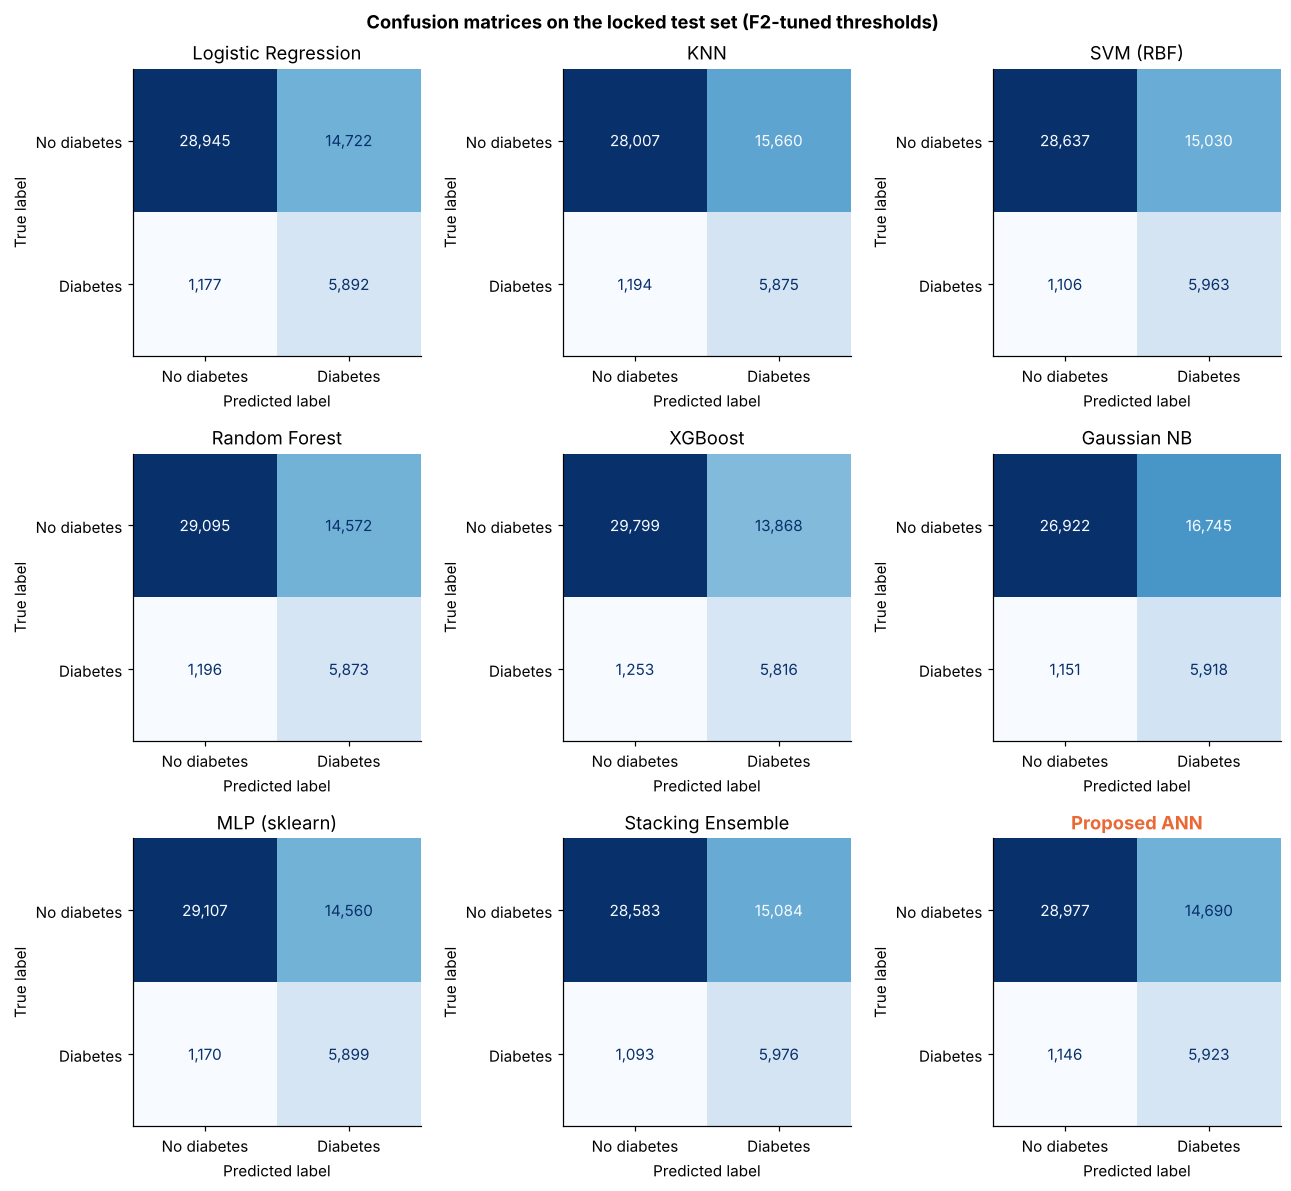

In [16]:
fig, axes = plt.subplots(3, 3, figsize=(12, 11))
for ax, m in zip(axes.ravel(), ORDER):
    cm = confusion_matrix(y_te, (P_te[m] >= THR[m]).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["No diabetes", "Diabetes"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
    ax.set_title(m, fontweight="bold" if m == "Proposed ANN" else None, color=ORANGE if m == "Proposed ANN" else "black"); ax.grid(False)
plt.suptitle("Confusion matrices on the locked test set (F2-tuned thresholds)", fontweight="bold"); plt.tight_layout()
plt.savefig(OUT_FIG / "r2_confusion_matrices.png", dpi=200); plt.show()

### 8.3 ROC and precision-recall curves

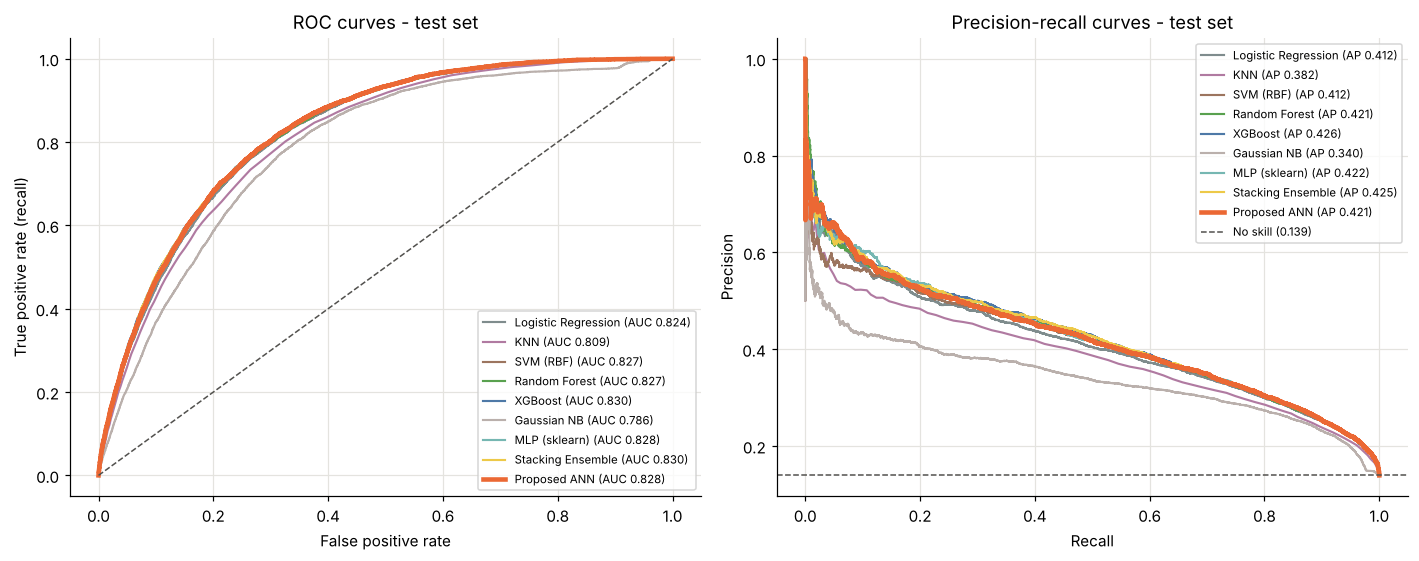

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
for m in ORDER:
    fpr, tpr, _ = roc_curve(y_te, P_te[m]); pr, rc, _ = precision_recall_curve(y_te, P_te[m])
    lw = 3 if m == "Proposed ANN" else 1.4
    ax[0].plot(fpr, tpr, color=MODEL_COLORS[m], lw=lw, label=f"{m} (AUC {results.loc[m, 'ROC-AUC']:.3f})")
    ax[1].plot(rc, pr, color=MODEL_COLORS[m], lw=lw, label=f"{m} (AP {results.loc[m, 'PR-AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], "--", color=GREY, lw=1); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate (recall)"); ax[0].set_title("ROC curves - test set")
ax[1].axhline(y_te.mean(), ls="--", color=GREY, lw=1, label=f"No skill ({y_te.mean():.3f})"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-recall curves - test set")
for a in ax: a.legend(fontsize=7.5, loc="lower right" if a is ax[0] else "upper right")
plt.tight_layout(); plt.savefig(OUT_FIG / "r2_roc_pr_curves.png", dpi=200); plt.show()

### 8.4 Calibration (reliability diagram)

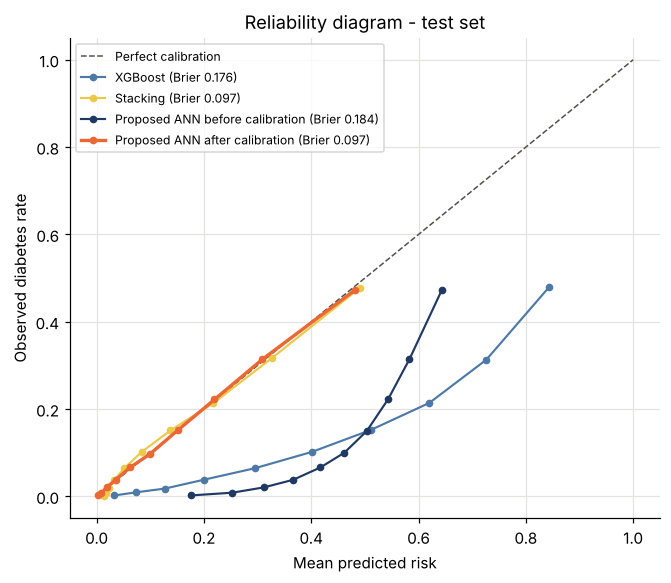

In [18]:
mu_te_raw, _ = mc_predict(ann, Xn_te)
fig, ax = plt.subplots(figsize=(6.2, 5.4))
ax.plot([0, 1], [0, 1], "--", color=GREY, lw=1, label="Perfect calibration")
for m, p, c, lab in [("XGBoost", P_te["XGBoost"], MODEL_COLORS["XGBoost"], f"XGBoost (Brier {brier_score_loss(y_te, P_te['XGBoost']):.3f})"),
                     ("Stacking", P_te["Stacking Ensemble"], MODEL_COLORS["Stacking Ensemble"], f"Stacking (Brier {brier_score_loss(y_te, P_te['Stacking Ensemble']):.3f})"),
                     ("ANN raw", mu_te_raw, NAVY, f"Proposed ANN before calibration (Brier {brier_score_loss(y_te, mu_te_raw):.3f})"),
                     ("ANN cal", mu_te, ORANGE, f"Proposed ANN after calibration (Brier {brier_score_loss(y_te, mu_te):.3f})")]:
    fp_, mp_ = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    ax.plot(mp_, fp_, "o-", color=c, lw=2.2 if "ANN cal" in m else 1.4, ms=4, label=lab)
ax.set_xlabel("Mean predicted risk"); ax.set_ylabel("Observed diabetes rate"); ax.set_title("Reliability diagram - test set"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_FIG / "r2_calibration.png", dpi=200); plt.show()

### 8.5 Statistical significance: McNemar's test and bootstrap confidence intervals

In [19]:
yh_ann = (P_te["Proposed ANN"] >= THR["Proposed ANN"]).astype(int)
rows = []
for m in ORDER[:-1]:
    yh = (P_te[m] >= THR[m]).astype(int)
    a_ok, b_ok = yh_ann == y_te, yh == y_te
    tbl = [[int((a_ok & b_ok).sum()), int((a_ok & ~b_ok).sum())], [int((~a_ok & b_ok).sum()), int((~a_ok & ~b_ok).sum())]]
    r = mcnemar(tbl, exact=False, correction=True)
    rows.append({"Baseline": m, "ANN right / baseline wrong": tbl[0][1], "ANN wrong / baseline right": tbl[1][0],
                 "chi2": round(r.statistic, 2), "p-value": f"{r.pvalue:.2e}", "Significant (p<0.05)": r.pvalue < 0.05})
mcn = pd.DataFrame(rows); mcn.to_csv(OUT_RES / "r2_mcnemar.csv", index=False); display(mcn)

B = 1000; rb = np.random.default_rng(SEED); n = len(y_te)
boot = {m: {"ROC-AUC": [], "PR-AUC": [], "Recall": []} for m in ["Proposed ANN", "XGBoost", "Stacking Ensemble"]}
for _ in range(B):
    i = rb.integers(0, n, n)
    for m in boot:
        boot[m]["ROC-AUC"].append(roc_auc_score(y_te[i], P_te[m][i])); boot[m]["PR-AUC"].append(average_precision_score(y_te[i], P_te[m][i]))
        boot[m]["Recall"].append(recall_score(y_te[i], P_te[m][i] >= THR[m]))
ci = pd.DataFrame({m: {k: f"{np.mean(v):.4f} [{np.percentile(v, 2.5):.4f}, {np.percentile(v, 97.5):.4f}]" for k, v in d.items()} for m, d in boot.items()}).T
ci.to_csv(OUT_RES / "r2_bootstrap_ci.csv"); ci

,Baseline,ANN right / baseline wrong,ANN wrong / baseline right,chi2,p-value,Significant (p<0.05)
0,Logistic Regression,1255,1192,1.57,2.10e-01,False
1,KNN,2992,1974,208.27,3.27e-47,True
2,SVM (RBF),1349,1049,37.28,1.02e-09,True
3,Random Forest,1249,1317,1.75,1.86e-01,False
4,XGBoost,718,1433,237.00,1.77e-53,True
5,Gaussian NB,4071,2011,697.05,1.31e-153,True
6,MLP (sklearn),1136,1242,4.64,3.13e-02,True
7,Stacking Ensemble,1178,837,57.37,3.61e-14,True


,ROC-AUC,PR-AUC,Recall
Proposed ANN,"0.8282 [0.8240, 0.8324]","0.4211 [0.4093, 0.4324]","0.8381 [0.8297, 0.8464]"
XGBoost,"0.8297 [0.8251, 0.8339]","0.4262 [0.4151, 0.4377]","0.8230 [0.8143, 0.8316]"
Stacking Ensemble,"0.8298 [0.8253, 0.8340]","0.4252 [0.4138, 0.4365]","0.8456 [0.8369, 0.8534]"


## 9. Uncertainty analysis - "refer to doctor"
Cases whose decision margin $|\mu - t|/\sigma$ is below $\tau$ are referred rather than classified. If the uncertainty is meaningful, the model should be wrong more often on referred cases. For comparison, the naive rule "refer the 10% with the largest $\sigma$" is also evaluated.

,cases,share,error rate,recall,diabetes rate
Accepted (model decides),45543.0,0.8976,0.2908,0.864,0.1409
Referred to doctor,5193.0,0.1024,0.4991,0.580,0.1252


,referred,error rate referred,error rate accepted
Margin rule |mu - t|/sigma < tau (used),5193.0,0.4991,0.2908
Naive rule sigma > 90th pct,5145.0,0.5403,0.2864


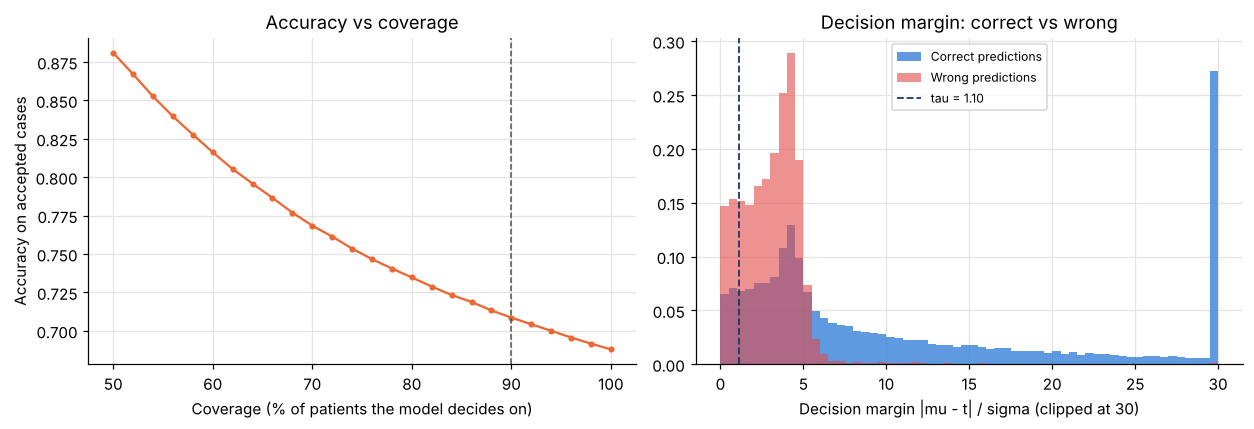

In [20]:
m_te = margin(mu_te, sd_te, THR["Proposed ANN"])
refer = m_te < TAU
yh = (mu_te >= THR["Proposed ANN"]).astype(int)
unc = pd.DataFrame({
    "Accepted (model decides)": {"cases": int((~refer).sum()), "share": (~refer).mean(), "error rate": (yh[~refer] != y_te[~refer]).mean(),
                                 "recall": recall_score(y_te[~refer], yh[~refer]), "diabetes rate": y_te[~refer].mean()},
    "Referred to doctor": {"cases": int(refer.sum()), "share": refer.mean(), "error rate": (yh[refer] != y_te[refer]).mean(),
                           "recall": recall_score(y_te[refer], yh[refer]), "diabetes rate": y_te[refer].mean()},
}).T
unc.to_csv(OUT_RES / "r2_uncertainty.csv"); display(unc.round(4))
naive = sd_te > np.quantile(sd_val, 0.90)
cmp_ = pd.DataFrame({
    "Margin rule |mu - t|/sigma < tau (used)": {"referred": int(refer.sum()), "error rate referred": (yh[refer] != y_te[refer]).mean(), "error rate accepted": (yh[~refer] != y_te[~refer]).mean()},
    "Naive rule sigma > 90th pct": {"referred": int(naive.sum()), "error rate referred": (yh[naive] != y_te[naive]).mean(), "error rate accepted": (yh[~naive] != y_te[~naive]).mean()},
}).T
cmp_.to_csv(OUT_RES / "r2_abstention_rules.csv"); display(cmp_.round(4))

cov, acc_c, err_c = [], [], []
order = np.argsort(-m_te)   # most certain decisions first
for q in np.linspace(0.5, 1.0, 26):
    keep = order[: int(q * n)]
    cov.append(q); acc_c.append(accuracy_score(y_te[keep], yh[keep])); err_c.append(roc_auc_score(y_te[keep], mu_te[keep]))
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
ax[0].plot(np.array(cov) * 100, acc_c, "o-", color=ORANGE, ms=3); ax[0].axvline(90, ls="--", color=GREY, lw=1)
ax[0].set_xlabel("Coverage (% of patients the model decides on)"); ax[0].set_ylabel("Accuracy on accepted cases"); ax[0].set_title("Accuracy vs coverage")
bins = np.linspace(0, 30, 61)
ax[1].hist(np.clip(m_te[y_te == yh], 0, 30), bins=bins, alpha=0.75, color=BLUE, density=True, label="Correct predictions")
ax[1].hist(np.clip(m_te[y_te != yh], 0, 30), bins=bins, alpha=0.6, color=RED, density=True, label="Wrong predictions")
ax[1].axvline(TAU, ls="--", color=NAVY, lw=1.2, label=f"tau = {TAU:.2f}"); ax[1].set_xlabel("Decision margin |mu - t| / sigma (clipped at 30)"); ax[1].set_title("Decision margin: correct vs wrong"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_FIG / "r2_uncertainty.png", dpi=200); plt.show()

## 10. Explainability - SHAP, per-patient explanation and what-if analysis

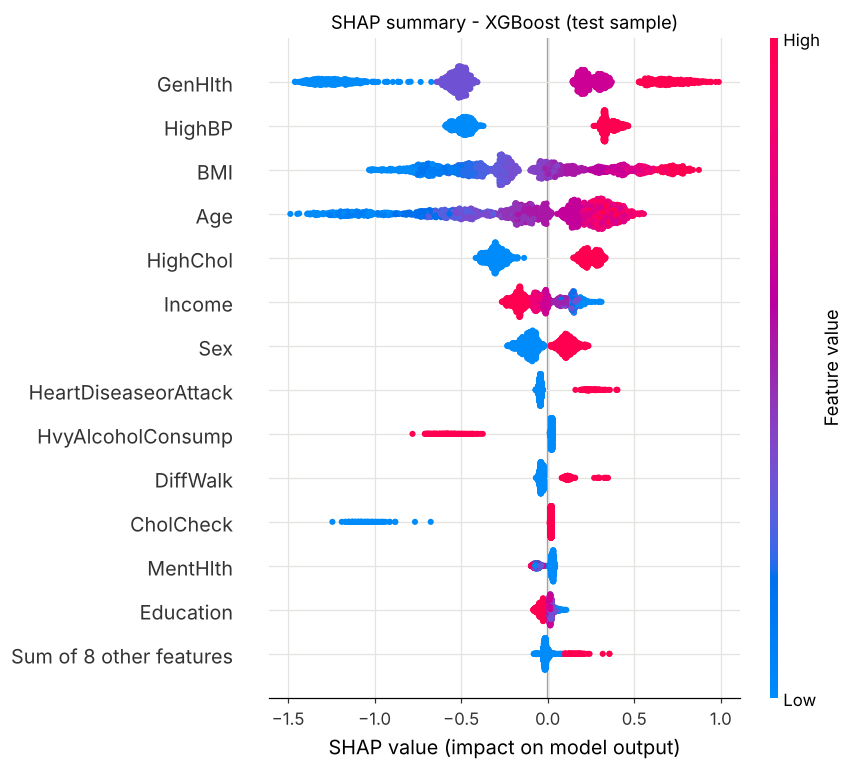

In [21]:
xs = np.random.default_rng(SEED).choice(len(y_te), 2000, replace=False)
expl_x = shap.TreeExplainer(models["XGBoost"])
sv_x = expl_x(X_te[xs])
sv_x.feature_names = FEATURES
plt.figure(); shap.plots.beeswarm(sv_x, max_display=14, show=False); plt.title("SHAP summary - XGBoost (test sample)")
plt.tight_layout(); plt.savefig(OUT_FIG / "r2_shap_xgb_beeswarm.png", dpi=200, bbox_inches="tight"); plt.show()

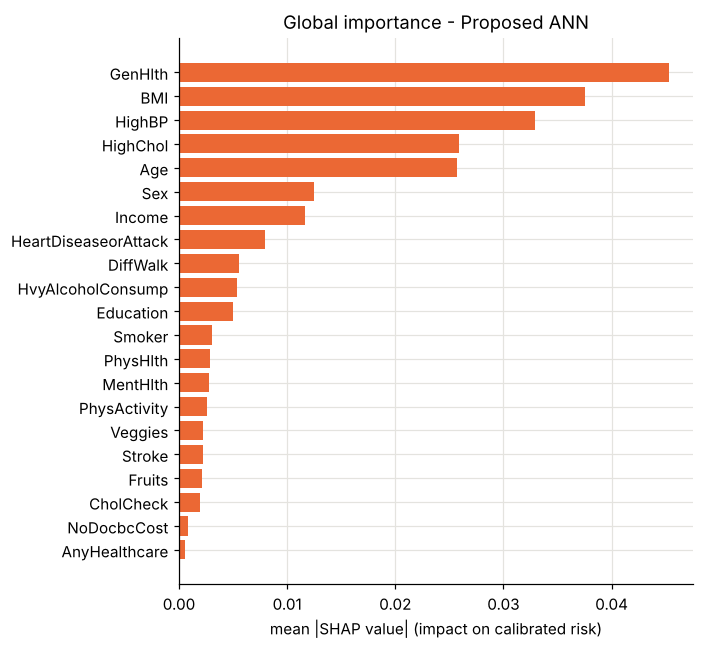

In [22]:
def ann_risk(Xraw_nn):
    return mc_predict(ann, np.asarray(Xraw_nn), cal=CAL, passes=10)[0]

bg = shap.maskers.Independent(Xn_fit[np.random.default_rng(SEED).choice(len(y_fit), 100, replace=False)])
xs_a = xs[:300]
expl_a = shap.PermutationExplainer(ann_risk, bg, max_evals=2 * len(FEATURES) + 1, seed=SEED)
sv_a = expl_a(Xn_te[xs_a], silent=True); sv_a.feature_names = FEATURES
imp = pd.Series(np.abs(sv_a.values).mean(0), index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.barh(imp.index, imp.values, color=ORANGE); ax.set_xlabel("mean |SHAP value| (impact on calibrated risk)"); ax.set_title("Global importance - Proposed ANN")
plt.tight_layout(); plt.savefig(OUT_FIG / "r2_shap_ann_global.png", dpi=200); plt.show()
imp.sort_values(ascending=False).round(4).to_csv(OUT_RES / "r2_shap_ann_importance.csv")

Patient #38735: calibrated risk 71.7%, uncertainty 0.126, decision margin 4.7 -> model decides; true label 1


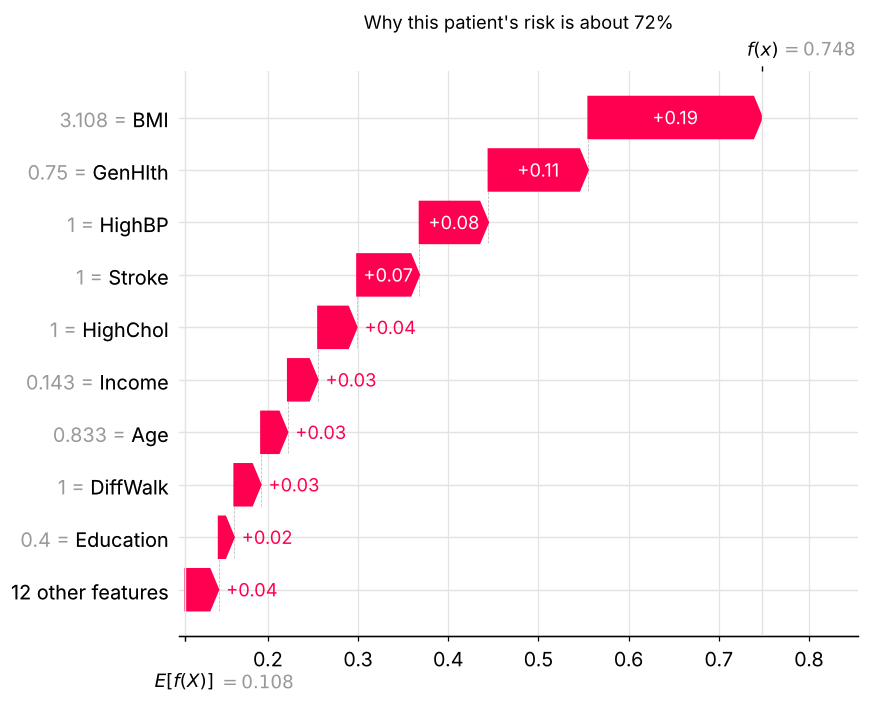

In [23]:
# Per-patient explanation: the test respondent with the highest calibrated risk among accepted (non-referred) cases in the SHAP sample
cand = [k for k, i in enumerate(xs_a) if not refer[i]]
k = max(cand, key=lambda k: mu_te[xs_a[k]]); i = xs_a[k]
mi, si = mc_predict(ann, Xn_te[[i]], cal=CAL)   # single-row MC estimate (same call as the what-if table below)
print(f"Patient #{i}: calibrated risk {mi[0]:.1%}, uncertainty {si[0]:.3f}, decision margin {margin(mi[0], si[0], THR['Proposed ANN']):.1f} -> {'refer' if margin(mi[0], si[0], THR['Proposed ANN']) < TAU else 'model decides'}; true label {y_te[i]}")
plt.figure(); shap.plots.waterfall(sv_a[k], max_display=10, show=False); plt.title(f"Why this patient's risk is about {mi[0]:.0%}")
plt.tight_layout(); plt.savefig(OUT_FIG / "r2_shap_patient_waterfall.png", dpi=200, bbox_inches="tight"); plt.show()

In [24]:
# What-if analysis on the same patient: change modifiable factors and re-score with the calibrated, uncertainty-aware model
base = test.iloc[[i]][FEATURES].copy()
scen = {"Current profile": {}, "BMI - 5": {"BMI": max(12, int(base.BMI.iloc[0]) - 5)}, "Physically active": {"PhysActivity": 1},
        "Blood pressure controlled": {"HighBP": 0}, "Cholesterol controlled": {"HighChol": 0},
        "All of the above": {"BMI": max(12, int(base.BMI.iloc[0]) - 5), "PhysActivity": 1, "HighBP": 0, "HighChol": 0}}
wi = []
for name, ch in scen.items():
    row = base.copy()
    for c, v in ch.items(): row[c] = v
    m_, s_ = mc_predict(ann, prep.transform(row, nn=True), cal=CAL)
    wi.append({"scenario": name, "calibrated risk": round(float(m_[0]), 4), "uncertainty": round(float(s_[0]), 4), "refer?": bool(margin(m_[0], s_[0], THR["Proposed ANN"]) < TAU)})
wi = pd.DataFrame(wi); wi.to_csv(OUT_RES / "r2_what_if.csv", index=False)
print("Patient profile:", base.iloc[0].to_dict()); wi

Patient profile: {'HighBP': 1, 'HighChol': 1, 'CholCheck': 1, 'Smoker': 0, 'Stroke': 1, 'HeartDiseaseorAttack': 0, 'PhysActivity': 0, 'Fruits': 1, 'Veggies': 0, 'HvyAlcoholConsump': 0, 'AnyHealthcare': 1, 'NoDocbcCost': 0, 'DiffWalk': 1, 'Sex': 0, 'BMI': 47, 'MentHlth': 0, 'PhysHlth': 30, 'GenHlth': 4, 'Age': 11, 'Education': 3, 'Income': 2}


,scenario,calibrated risk,uncertainty,refer?
0,Current profile,0.7171,0.1257,False
1,BMI - 5,0.6851,0.1260,False
2,Physically active,0.6870,0.1301,False
3,Blood pressure controlled,0.6332,0.1238,False
4,Cholesterol controlled,0.6052,0.1165,False
5,All of the above,0.4257,0.0921,False


## 11. Bias audit and false-negative analysis

In [25]:
yh_t = (mu_te >= THR["Proposed ANN"]).astype(int)
def grp_metrics(mask):
    yt, yp = y_te[mask], yh_t[mask]; tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    return {"n": int(mask.sum()), "diabetes rate": yt.mean(), "recall": tp / max(tp + fn, 1), "specificity": tn / max(tn + fp, 1)}
age_band = pd.cut(test.Age, [0, 4, 8, 10, 13], labels=["18-39", "40-59", "60-69", "70+"])
inc_band = pd.cut(test.Income, [0, 3, 6, 8], labels=["< $20k", "$20-50k", "> $50k"])
audit = []
for col, ser in [("Sex", test.Sex.map({0: "Female", 1: "Male"})), ("Age band", age_band), ("Income band", inc_band)]:
    for g in ser.cat.categories if hasattr(ser, "cat") else sorted(ser.unique()):
        audit.append({"attribute": col, "group": g, **grp_metrics((ser == g).to_numpy())})
audit = pd.DataFrame(audit).round(4); audit.to_csv(OUT_RES / "r2_bias_audit.csv", index=False); display(audit)

fn = (y_te == 1) & (yh_t == 0); tp = (y_te == 1) & (yh_t == 1)
fna = pd.DataFrame({"missed diabetics (FN)": test.loc[fn, FEATURES].mean(), "detected diabetics (TP)": test.loc[tp, FEATURES].mean()})
fna["difference"] = fna.iloc[:, 0] - fna.iloc[:, 1]
print(f"False negatives: {fn.sum():,} of {(y_te == 1).sum():,} diabetics ({fn.sum() / (y_te == 1).sum():.1%})")
fna.reindex(fna["difference"].abs().sort_values(ascending=False).index).head(10).round(3)

,attribute,group,n,diabetes rate,recall,specificity
0,Sex,Female,28443,0.1289,0.8227,0.6991
1,Sex,Male,22293,0.1526,0.8542,0.6170
2,Age band,18-39,7585,0.0279,0.4481,0.9451
3,Age band,40-59,18668,0.1093,0.7691,0.7455
4,Age band,60-69,13032,0.1899,0.8735,0.5529
5,Age band,70+,11451,0.2045,0.8954,0.4144
6,Income band,< $20k,7463,0.2419,0.9285,0.4031
7,Income band,$20-50k,16513,0.1634,0.8733,0.5654
8,Income band,> $50k,26760,0.0959,0.7368,0.7805


False negatives: 1,146 of 7,069 diabetics (16.2%)


,missed diabetics (FN),detected diabetics (TP),difference
PhysHlth,2.654,8.984,-6.330
BMI,27.533,32.789,-5.256
MentHlth,2.416,4.749,-2.332
Age,8.234,9.607,-1.373
Income,6.305,5.026,1.279
GenHlth,2.345,3.474,-1.130
HighBP,0.313,0.839,-0.526
Education,5.151,4.686,0.465
DiffWalk,0.076,0.422,-0.346
HighChol,0.380,0.723,-0.343


## 12. Saving the model for the application

In [26]:
np.savez(OUT_MODEL / "proposed_ann.npz", *[p for p, _, _ in ann.params()])
cfg = {"features": FEATURES, "continuous": CONTINUOUS, "ordinal": ORDINAL, "bmi_clip": [float(prep.lo_), float(prep.hi_)],
       "mu": prep.mu_.to_dict(), "sd": prep.sd_.to_dict(), "ordinal_min": prep.omin_.to_dict(), "ordinal_max": prep.omax_.to_dict(),
       "hidden": [64, 32], "dropout": 0.2, "temperature": TEMP, "bias": BIAS, "threshold": THR["Proposed ANN"], "tau": TAU, "mc_passes": T_MC,
       "focal_alpha": ALPHA, "focal_gamma": GAMMA}
json.dump(cfg, open(OUT_MODEL / "proposed_ann_config.json", "w"), indent=2)
summary = {"split": {"train": len(train), "test": len(test), "fit": len(fit), "val": len(val), "shared_rows": shared},
           "gradient_check": gc, "focal_search": search.to_dict("records"), "alpha": ALPHA, "gamma": GAMMA, "temperature": TEMP, "bias": BIAS,
           "tau": TAU, "thresholds": THR, "tuning": {k: [str(v[0]), v[1]] for k, v in tuning.items()}, "fit_time_s": fit_time,
           "ann_epochs": int(len(ann_hist)), "ann_best_val_prauc": ann_best, "runtime_min": (time.time() - T0) / 60}
json.dump(summary, open(OUT_RES / "r2_summary.json", "w"), indent=2, default=float)
print(f"Saved model + config. Total notebook runtime: {(time.time() - T0) / 60:.1f} min")

Saved model + config. Total notebook runtime: 8.9 min
